<a href="https://colab.research.google.com/github/pranav-1205/CSL701-Roll_No_CS47_Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_7_Principal_Component_Analysis_(PCA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Experiment Number 7


Student Name : Pranav Vivek Sadwelkar

Batch : CS - 03


Roll Number : CS 47



Aim

To implement Principal Component Analysis (PCA) for dimensionality reduction on the Breast Cancer Wisconsin (Diagnostic) dataset, visualize the high-dimensional feature space in a reduced 2D plane, and evaluate its impact on classification performance.

## Objectives

1. To understand the concepts of dimensionality reduction, feature correlation, and Principal Component Analysis.

2. To preprocess, clean, and scale high-dimensional real-world data using StandardScaler.

3. To implement PCA using Python to compress feature dimensions from 30 continuous features down to 2 principal components.

4. To calculate and plot the explained variance ratio and cumulative explained variance.

5. To visualize the transformed 2D dataset and analyze class separability.

6. To evaluate and compare classification model performance (e.g., Logistic Regression) before and after applying PCA.

# Relevant Theory

### Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is an unsupervised machine learning technique used for dimensionality reduction. It transforms a dataset containing a large set of correlated features into a smaller set of uncorrelated variables called Principal Components ($PCs$), while preserving as much data variance as possible.

Mathematical Steps:

1. Standardization: Scale each feature to have a mean of 0 ($\mu = 0$) and standard deviation of 1 ($\sigma = 1$).

2. Covariance Matrix: Compute the covariance matrix $C$ to quantify feature correlations:$$C = \frac{1}{n-1} X^T X$$

3. Eigen decomposition: Compute eigenvalues ($\lambda$) and eigenvectors ($v$) of matrix $C$:$$C v = \lambda v$$

    * Eigenvectors represent the direction of the principal axes.
    * Eigenvalues indicate the amount of variance along those axes.
4. Projection: Project original data $X$ onto top $k$ principal component directions $W$:$$X_{\text{pca}} = X \cdot W$$

###Dataset Information


1. Dataset Name: Breast Cancer Wisconsin (Diagnostic) Dataset

2. Kaggle Link: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

3. Classes: 2 binary classes (Malignant [$M$] and Benign [$B$])

4. Features: 30 continuous features computed from digitized images of fine needle aspirates (FNA) of a breast mass (e.g., radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, concavity_mean, etc.).

5. Non-Feature Columns: id (identifier) and Unnamed: 32 (empty column).

# Task 1: Import Libraries and Load Dataset

Import core Python libraries (numpy, pandas, matplotlib, seaborn, sklearn) and load data.csv obtained from Kaggle.

---

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("data.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()


Dataset loaded successfully.
Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


# Task 2: Explore the Dataset

Inspect missing values, view dataset summary statistics, check column data types, and inspect target class distributions (diagnosis).

Missing values:
 id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_wors

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN



Diagnosis distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


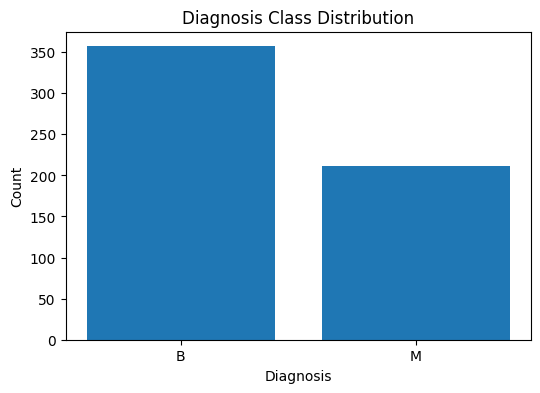

In [3]:
print('Missing values:\n', df.isnull().sum())
print('\nData types:\n', df.dtypes)
print('\nSummary statistics:')
display(df.describe())
print('\nDiagnosis distribution:')
counts = df['diagnosis'].value_counts()
print(counts)
plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values)
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.title('Diagnosis Class Distribution')
plt.show()

# Task 3: Data Cleaning and Feature/Target Selection

Drop metadata columns (id and Unnamed: 32). Convert the categorical target column (diagnosis: 'M'/'B') into numerical values (1/0) and separate feature matrix $X$ (30 features) from label vector $y$.   

In [4]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']
print('Feature matrix shape:', X.shape)
print('Target shape:', y.shape)
print('Target values:', y.unique())

Feature matrix shape: (569, 30)
Target shape: (569,)
Target values: [1 0]


# Task 4: Standardize Features

Apply StandardScaler to transform all 30 numeric features so they have zero mean and unit variance ($\mu=0, \sigma=1$).

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled feature matrix shape:', X_scaled.shape)
print('First 5 feature means:', X_scaled.mean(axis=0)[:5])
print('First 5 feature standard deviations:', X_scaled.std(axis=0)[:5])

Scaled feature matrix shape: (569, 30)
First 5 feature means: [-1.37363271e-16  6.86816353e-17 -1.24875700e-16 -2.18532476e-16
 -8.36667193e-16]
First 5 feature standard deviations: [1. 1. 1. 1. 1.]


# Task 5: Implement PCA (30D to 2D)

Use sklearn.decomposition.PCA to reduce feature dimensions from 30 down to 2 principal components ($PC_1$ and $PC_2$).

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Original dimensions:', X_scaled.shape[1])
print('Reduced dimensions:', X_pca.shape[1])
print('First 5 PCA rows:\n', X_pca[:5])

Original dimensions: 30
Reduced dimensions: 2
First 5 PCA rows:
 [[ 9.19283683  1.94858307]
 [ 2.3878018  -3.76817174]
 [ 5.73389628 -1.0751738 ]
 [ 7.1229532  10.27558912]
 [ 3.93530207 -1.94807157]]


# Task 6: Analyze Explained Variance Ratio

Compute and print the variance explained by $PC_1$ and $PC_2$, along with the cumulative variance retained.


PC1 explained variance: 0.4427 (44.27%)
PC2 explained variance: 0.1897 (18.97%)
Cumulative variance retained: 0.6324 (63.24%)
Components needed to retain 95% variance: 10


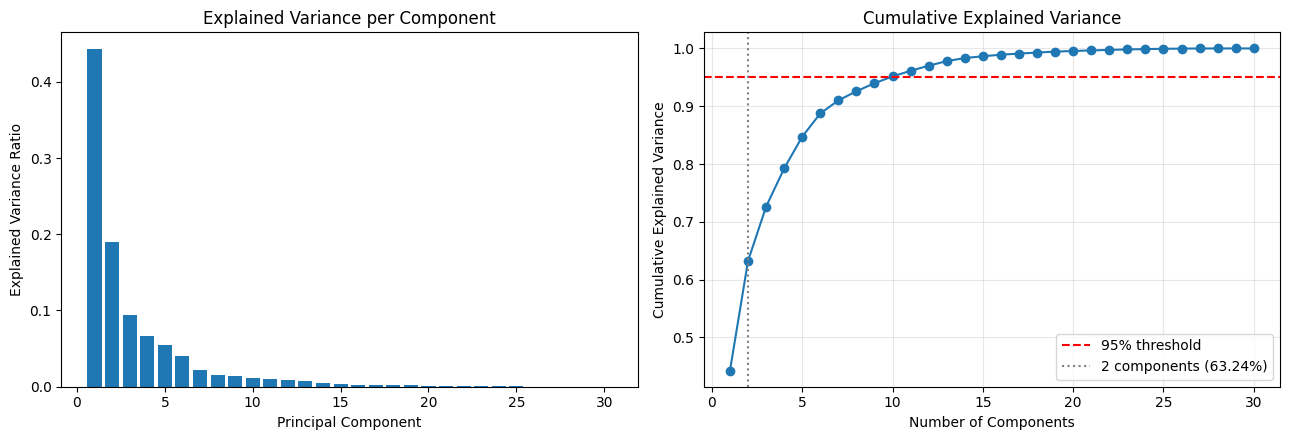

In [7]:
pc1_var, pc2_var = pca.explained_variance_ratio_
cumulative_var = pca.explained_variance_ratio_.sum()
print(f'PC1 explained variance: {pc1_var:.4f} ({pc1_var*100:.2f}%)')
print(f'PC2 explained variance: {pc2_var:.4f} ({pc2_var*100:.2f}%)')
print(f'Cumulative variance retained: {cumulative_var:.4f} ({cumulative_var*100:.2f}%)')

# Full PCA (all 30 components) to show how variance accumulates
pca_full = PCA().fit(X_scaled)
ratio = pca_full.explained_variance_ratio_
cum = np.cumsum(ratio)
n95 = int(np.argmax(cum >= 0.95)) + 1
print(f'Components needed to retain 95% variance: {n95}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(ratio) + 1), ratio)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Explained Variance per Component')

axes[1].plot(range(1, len(cum) + 1), cum, marker='o')
axes[1].axhline(0.95, color='red', linestyle='--', label='95% threshold')
axes[1].axvline(2, color='gray', linestyle=':', label='2 components (63.24%)')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Task 7: Visualize PCA Transformed Boundary / Scatter Plot

Create a 2D scatter plot with $PC_1$ on the x-axis and $PC_2$ on the y-axis, hue-coded by tumor diagnosis (Malignant vs. Benign).

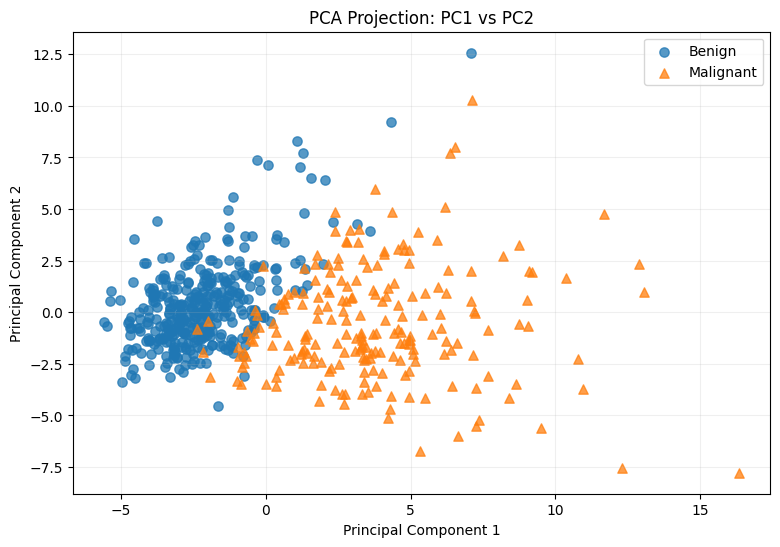

In [8]:
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Diagnosis'] = y.map({0: 'Benign', 1: 'Malignant'})

plt.figure(figsize=(9,6))
for label, marker in [('Benign', 'o'), ('Malignant', '^')]:
    subset = pca_df[pca_df['Diagnosis'] == label]
    plt.scatter(subset['PC1'], subset['PC2'], marker=marker, s=45, label=label, alpha=0.75)
plt.title('PCA Projection: PC1 vs PC2')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Task 8: Train Classifier on Raw High-Dimensional Data (30 Features)

Split the original scaled 30-feature dataset into training and testing sets. Train a Logistic Regression model and obtain baseline performance metrics.

In [9]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

log_raw = LogisticRegression(max_iter=2000, random_state=42)
log_raw.fit(X_train_raw, y_train_raw)
y_pred_raw = log_raw.predict(X_test_raw)

raw_accuracy = accuracy_score(y_test_raw, y_pred_raw)
print(f'Baseline Logistic Regression Accuracy: {raw_accuracy:.4f} ({raw_accuracy*100:.2f}%)')

Baseline Logistic Regression Accuracy: 0.9649 (96.49%)


# Task 9: Train Classifier on PCA Transformed Data (2 Features)

Split the 2-component PCA dataset into training and testing sets. Train a Logistic Regression model using only $PC_1$ and $PC_2$.

In [10]:
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca, y, test_size=0.2, random_state=42, stratify=y
)

log_pca = LogisticRegression(max_iter=2000, random_state=42)
log_pca.fit(X_train_pca, y_train_pca)
y_pred_pca = log_pca.predict(X_test_pca)

pca_accuracy = accuracy_score(y_test_pca, y_pred_pca)
print(f'PCA Logistic Regression Accuracy: {pca_accuracy:.4f} ({pca_accuracy*100:.2f}%)')

PCA Logistic Regression Accuracy: 0.9386 (93.86%)


# Task 10: Compare Classifier Performance

Compare the performance of the model before PCA (30 features) vs. after PCA (2 components) using:   

*   Accuracy Score
*   Confusion Matrix
*   Classification Report (Precision, Recall, F1-Score)  



=== Accuracy Comparison ===
Before PCA (30 features): 0.9649 (96.49%)
After PCA (2 components): 0.9386 (93.86%)
Accuracy difference: -2.63 percentage points


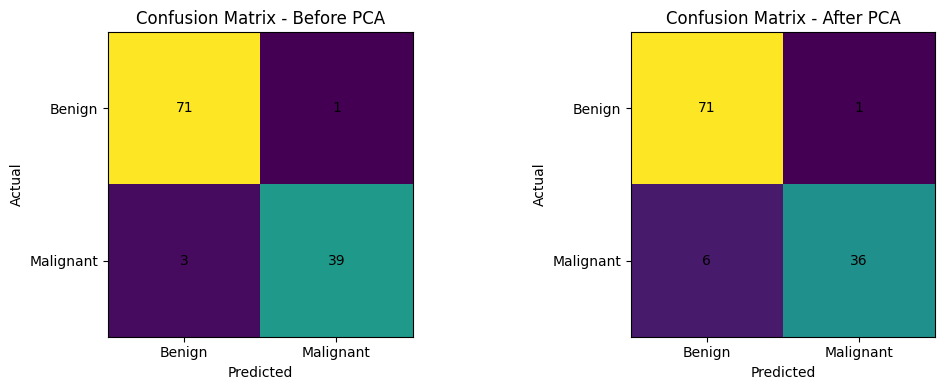


Classification Report - Before PCA
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Classification Report - After PCA
              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        72
   Malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



In [11]:
print('=== Accuracy Comparison ===')
print(f'Before PCA (30 features): {raw_accuracy:.4f} ({raw_accuracy*100:.2f}%)')
print(f'After PCA (2 components): {pca_accuracy:.4f} ({pca_accuracy*100:.2f}%)')
print(f'Accuracy difference: {(pca_accuracy-raw_accuracy)*100:.2f} percentage points')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cm, title in [
    (axes[0], confusion_matrix(y_test_raw, y_pred_raw), 'Confusion Matrix - Before PCA'),
    (axes[1], confusion_matrix(y_test_pca, y_pred_pca), 'Confusion Matrix - After PCA')]:
    im = ax.imshow(cm, interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0, 1], ['Benign', 'Malignant'])
    ax.set_yticks([0, 1], ['Benign', 'Malignant'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout()
plt.show()

print('\nClassification Report - Before PCA')
print(classification_report(y_test_raw, y_pred_raw, target_names=['Benign', 'Malignant']))
print('Classification Report - After PCA')
print(classification_report(y_test_pca, y_pred_pca, target_names=['Benign', 'Malignant']))

# Conclusion

The experiment demonstrated Principal Component Analysis (PCA) on the Breast Cancer Wisconsin (Diagnostic) dataset. The data was cleaned (the `id` and empty `Unnamed: 32` columns were dropped), the diagnosis was encoded as 0/1, and all 30 features were standardized before applying PCA.

Reducing the 30 features to 2 principal components retained about 63.2% of the total variance (PC1 = 44.3%, PC2 = 19.0%); roughly 10 components are needed to retain 95%. The 2-D scatter plot shows Malignant and Benign tumors forming largely distinct groups, with some overlap in the middle.

Logistic Regression reached 96.49% accuracy on the original 30 features and 93.86% on only 2 principal components, a drop of about 2.6 percentage points. The loss was mainly in Malignant recall (0.93 to 0.86), which matters in a medical setting because it means more missed malignant cases. PCA therefore greatly reduces model complexity and visualizes the data well while keeping good accuracy, but some information is lost when compressing to 2 components.